# Credit Card Fraud — Exploratory Data Analysis

Source: `mlg-ulb/creditcardfraud` (Kaggle), loaded via `fraud_pipeline.ingestion.loader`.

This notebook follows a label-informed anomaly-analysis strategy, in six steps:

1. **Shape and structure** — get oriented: row count, columns, dtypes, data quality.
2. **Class balance** — establish the fraud rate up front, since it governs every
   evaluation choice downstream.
3. **Feature ranking by separation** — rank the anonymized `V` columns by how well each
   one separates fraud from normal (Cohen's d).
4. **Visual confirmation** — plot the top-ranked features to see the separation directly.
5. **Rule-based baseline** — turn that visual pattern into a measurable detector (an IQR
   rule), evaluated against `Class`.
6. **Time/Amount checks** — a quick look at whether fraud clusters by hour of day or
   transaction size.

See `docs/eda-strategies.md` for how this compares to the label-blind approach used in
`02_generic_skeleton.ipynb`.

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

from fraud_pipeline.ingestion.loader import load_transactions

df = load_transactions()
df.shape # (num_rows, num_columns)

(284807, 31)

## 1. Shape and structure

Before anything else: how big is this dataset, what type is each column, and does it look
clean? This step never depends on knowing what we're trying to predict — it's the same
first move on any new dataset, labeled or not.

In [18]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [20]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## 2. Class balance

Now the target: how rare is fraud, exactly? This number (~0.17%) is the single most
important fact about this dataset — it's why accuracy is a useless metric here, and why
every evaluation below uses recall / false-positive rate instead. Right after it, a quick
first look at whether `Amount` differs by class too, before the more rigorous feature-level
analysis in the next section.

In [21]:
df["Class"].value_counts(normalize=True)

Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64

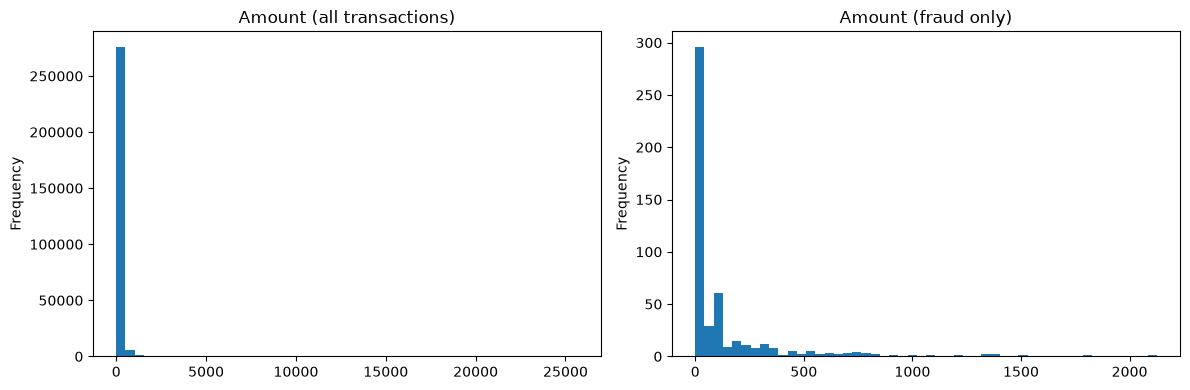

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["Amount"].plot(kind="hist", bins=50, ax=axes[0], title="Amount (all transactions)")
df.loc[df["Class"] == 1, "Amount"].plot(kind="hist", bins=50, ax=axes[1], title="Amount (fraud only)")
plt.tight_layout()

## 3. Feature ranking by separation

### Which features actually separate fraud from normal?

The `V1`–`V28` columns are PCA components of the original (undisclosed) transaction
features, so we can't interpret them by name — but we can still ask: for which of these
components do fraud and normal transactions have visibly different distributions?

We'll use **Cohen's d**: the difference in class means, scaled by the pooled standard
deviation. It's a standard way to rank features by how well they separate two groups,
independent of each feature's raw scale (important here since some `V` columns have very
different variances).

In [23]:
feature_cols = [c for c in df.columns if c.startswith("V")]

fraud = df[df["Class"] == 1]
normal = df[df["Class"] == 0]


def cohens_d(a, b):
    pooled_std = ((a.std() ** 2 + b.std() ** 2) / 2) ** 0.5
    return (a.mean() - b.mean()) / pooled_std


separation = pd.Series(
    {col: cohens_d(fraud[col], normal[col]) for col in feature_cols}
).sort_values(key=abs, ascending=False)

separation.head(10)

V14   -2.259076
V4     2.013335
V11    1.882183
V12   -1.866983
V10   -1.606058
V16   -1.482429
V3    -1.372580
V17   -1.346956
V9    -1.340457
V2     1.117825
dtype: float64

## 4. Visual confirmation

A larger `|d|` means fraud and normal transactions sit further apart on that feature,
relative to how spread out each group is. `|d| > 0.8` is conventionally considered a
"large" effect. Whatever comes out on top here is the feature set worth visualizing
directly.

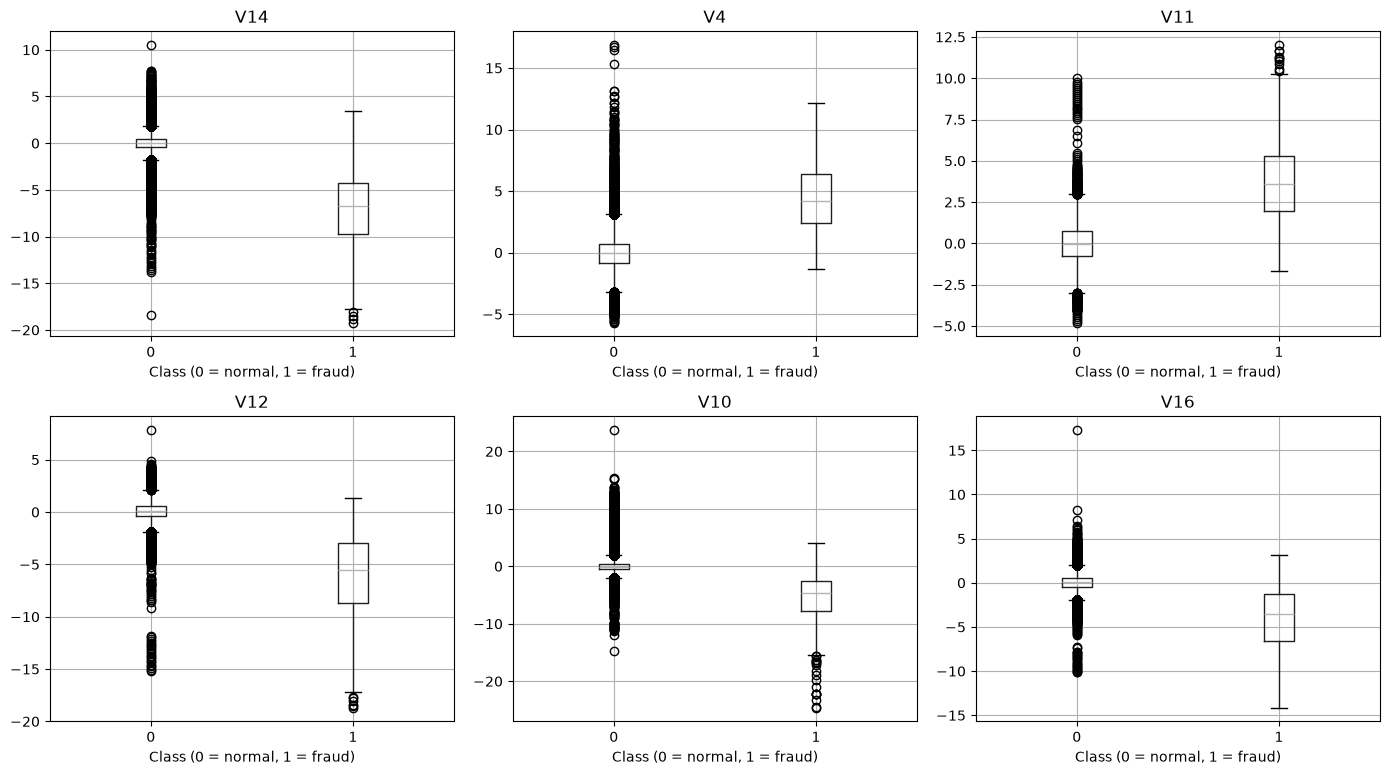

In [24]:
top_features = separation.abs().sort_values(ascending=False).index[:6].tolist()

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, col in zip(axes.flat, top_features):
    df.boxplot(column=col, by="Class", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("Class (0 = normal, 1 = fraud)")
plt.suptitle("")
plt.tight_layout()

Boxplots make the separation concrete: for the top features, fraud's interquartile range
sits mostly outside normal's. That's the visual signature of an anomaly — not "extreme
values" in general, but extreme values *along specific dimensions*.

Next, project onto the two strongest features and look for actual cluster separation in
2D — this is the closest thing to "eyeballing the anomalies" directly.

Text(0.5, 1.0, 'V14 vs V4, colored by class')

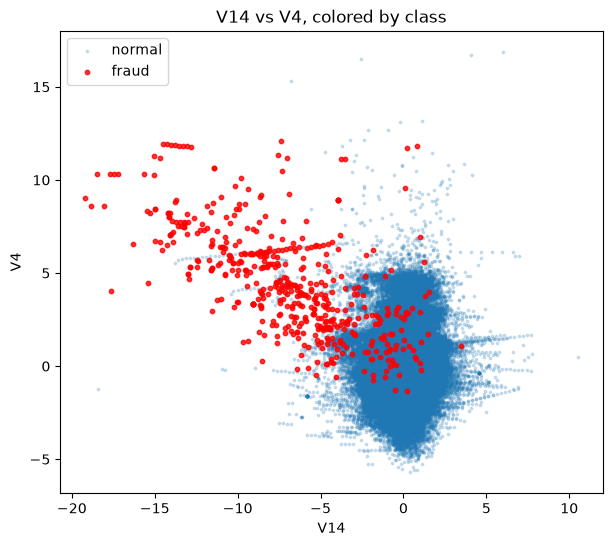

In [25]:
top2 = top_features[:2]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(normal[top2[0]], normal[top2[1]], s=3, alpha=0.2, label="normal")
ax.scatter(fraud[top2[0]], fraud[top2[1]], s=10, alpha=0.8, label="fraud", color="red")
ax.set_xlabel(top2[0])
ax.set_ylabel(top2[1])
ax.legend()
ax.set_title(f"{top2[0]} vs {top2[1]}, colored by class")

## 5. Rule-based baseline

### From "looks different" to a rule: IQR-based outlier flagging

Boxplots already hint at this: fraud tends to fall in the *tails* of these distributions.
Tukey's IQR rule formalizes "tail" — flag anything more than 1.5×IQR beyond the 25th/75th
percentile. This is a real (if primitive) unsupervised anomaly detector: it never looks at
`Class` to decide what's flagged, only at each feature's own distribution.

We *do* use `Class` afterward — but only to **evaluate** the rule, the same way we'll
evaluate Isolation Forest or an autoencoder in Phase 3. That's the general pattern for
anomaly detection: the detector is unsupervised, the evaluation is supervised (when labels
happen to be available, which in production fraud systems they often aren't, or arrive
late).

In [26]:
def iqr_outlier_mask(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (series < q1 - k * iqr) | (series > q3 + k * iqr)


outlier_flags = pd.DataFrame({col: iqr_outlier_mask(df[col]) for col in top_features})
flagged = outlier_flags.any(axis=1)

recall = flagged[df["Class"] == 1].mean()
false_positive_rate = flagged[df["Class"] == 0].mean()
flag_volume = flagged.mean()

print(f"Fraud caught by the IQR rule (recall):        {recall:.1%}")
print(f"Normal transactions flagged (false positives): {false_positive_rate:.1%}")
print(f"Share of all transactions flagged:             {flag_volume:.1%}")

Fraud caught by the IQR rule (recall):        91.7%
Normal transactions flagged (false positives): 16.0%
Share of all transactions flagged:             16.1%


This is the core tradeoff every anomaly detector in this project will face: catching more
fraud (higher recall) generally means flagging more normal transactions too (higher false
positive rate). A rule built from just 6 hand-picked features, with no training, is already
a useful baseline to compare Phase 3 models against — if Isolation Forest can't beat this,
something's wrong.

## 6. Time/Amount checks

### Does *when* or *how much* matter?

`Time` is seconds elapsed since the first transaction (the dataset spans ~2 days), and
`Amount` is transaction value. Neither is a PCA component, so we can reason about them
directly.

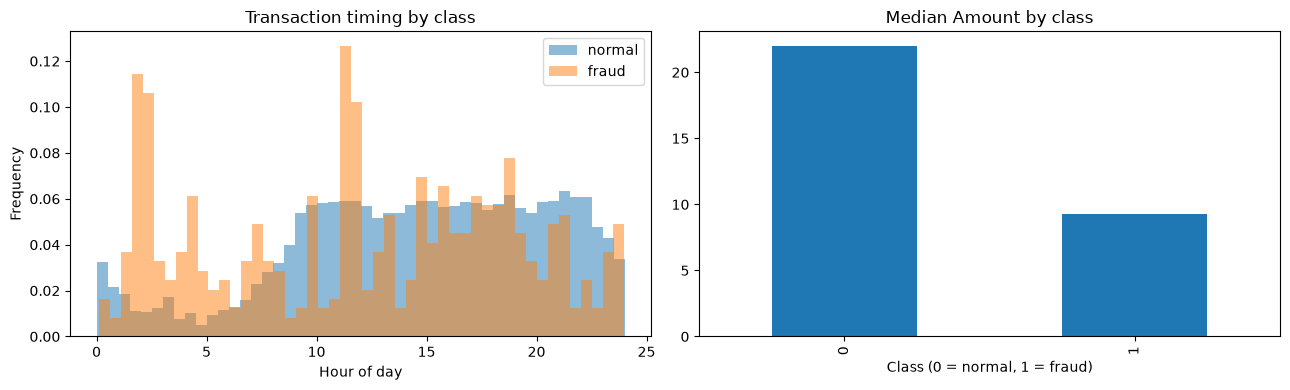

In [ ]:
df["hour"] = (df["Time"] % 86400) / 3600 # Extract hour from timestamp by taking the remainder of seconds in a day and converting to hours

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for cls, label in [(0, "normal"), (1, "fraud")]:
    df.loc[df["Class"] == cls, "hour"].plot(
        kind="hist", bins=48, alpha=0.5, density=True, label=label, ax=axes[0]
    )
axes[0].set_xlabel("Hour of day")
axes[0].set_title("Transaction timing by class")
axes[0].legend()

df.groupby("Class")["Amount"].median().plot(kind="bar", ax=axes[1], title="Median Amount by class")
axes[1].set_xlabel("Class (0 = normal, 1 = fraud)")

plt.tight_layout()

## Wrap-up: what this buys us for Phase 3

Everything above was descriptive statistics and plots — no model was trained. But it maps
directly onto how the Phase 3 models work:

- **Isolation Forest** generalizes the IQR rule: instead of us hand-picking 6 features and a
  fixed threshold, it randomly partitions *all* features and measures how few splits it
  takes to isolate a point. Points that split off quickly (in few cuts) score as anomalous —
  conceptually the same "sits in the tail" idea, done automatically across all 30 features
  at once.
- **Autoencoder** learns to compress and reconstruct normal transactions well; fraud, being
  statistically different (as we just measured with Cohen's d), reconstructs poorly. High
  reconstruction error ≈ our "flagged" outliers above.
- **XGBoost** is the odd one out — it's supervised, so it uses `Class` directly during
  training rather than just for evaluation. It's included as a ceiling: if labels are
  available, how much better can a fully supervised model do versus the unsupervised
  approaches above?

The IQR baseline's recall/false-positive numbers above are the number to beat once those
models exist.